# Model Evaluation and Comparison

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Why Evaluate Models?

Model evaluation tells us whether a model will **generalize** to new data:

- Assess model **accuracy**
- Compare **different models**
- Detect **overfitting** (memorising noise) or **underfitting** (missing real structure)

The golden rule: **never judge a model only on the data it was trained on.**

## 2. Regression Metrics

1. **Mean Squared Error**: $MSE = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2$
2. **Root Mean Squared Error**: $RMSE = \sqrt{MSE}$ (same units as $y$; penalises large errors)
3. **Mean Absolute Error**: $MAE = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$ (robust to outliers)
4. **R-squared**: $R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$ (share of variance explained)

## 3. Classification Metrics

From the confusion matrix (TP, FP, TN, FN):

$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}, \quad
\text{Precision} = \frac{TP}{TP + FP}, \quad
\text{Recall} = \frac{TP}{TP + FN}, \quad
F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}
$$

- **Precision**: of everything we flagged as positive, how much really was positive?
- **Recall (sensitivity)**: of all real positives, how many did we catch?
- **ROC curve**: true-positive rate vs false-positive rate across **all** thresholds; **AUC** is the area under it (0.5 = random guessing, 1 = perfect).

## 4. Evaluating a Regression Model

    metric  value
       MSE 0.0329
      RMSE 0.1813
       MAE 0.1378
 R-squared 0.9953


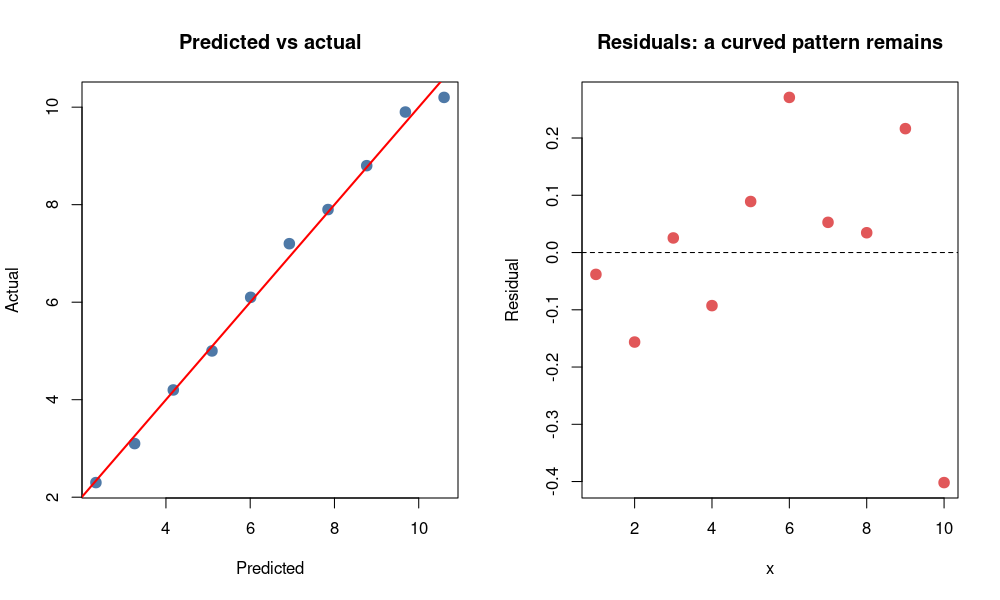

In [2]:
set.seed(123)
x <- 1:10
y <- c(2.3, 3.1, 4.2, 5.0, 6.1, 7.2, 7.9, 8.8, 9.9, 10.2)

lm_model <- lm(y ~ x)
y_pred <- predict(lm_model)

MSE  <- mean((y - y_pred)^2)
RMSE <- sqrt(MSE)
MAE  <- mean(abs(y - y_pred))
R2   <- 1 - sum((y - y_pred)^2) / sum((y - mean(y))^2)

print(data.frame(metric = c("MSE", "RMSE", "MAE", "R-squared"), value = round(c(MSE, RMSE, MAE, R2), 4)),
      row.names = FALSE)

par(mfrow = c(1, 2))
plot(y_pred, y, pch = 19, cex = 1.4, col = "#4E79A7", main = "Predicted vs actual",
     xlab = "Predicted", ylab = "Actual"); abline(0, 1, col = "red", lwd = 2)
plot(x, y - y_pred, pch = 19, cex = 1.4, col = "#E15759", main = "Residuals: a curved pattern remains",
     xlab = "x", ylab = "Residual"); abline(h = 0, lty = 2)

## 5. Evaluating a Classification Model

We fit a logistic regression to the built-in `mtcars` data (predict a manual transmission, `am = 1`, from weight and horsepower), then compute every metric by hand.

In [3]:
clf <- glm(am ~ wt + hp, data = mtcars, family = binomial)
pred_prob  <- predict(clf, type = "response")
actual     <- mtcars$am

metrics_at <- function(threshold) {
  pred_class <- as.integer(pred_prob > threshold)
  TP <- sum(pred_class == 1 & actual == 1); TN <- sum(pred_class == 0 & actual == 0)
  FP <- sum(pred_class == 1 & actual == 0); FN <- sum(pred_class == 0 & actual == 1)
  precision <- TP / (TP + FP); recall <- TP / (TP + FN)
  c(threshold = threshold, accuracy = (TP + TN) / length(actual), precision = precision,
    recall = recall, F1 = 2 * precision * recall / (precision + recall))
}

pred_class <- as.integer(pred_prob > 0.5)
print(table(Predicted = pred_class, Actual = actual))
cat("\n")
print(round(t(sapply(c(0.3, 0.5, 0.7, 0.9), metrics_at)), 3))

         Actual
Predicted  0  1
        0 18  1
        1  1 12


     threshold accuracy precision recall    F1
[1,]       0.3    0.969     0.929  1.000 0.963
[2,]       0.5    0.938     0.923  0.923 0.923
[3,]       0.7    0.906     0.917  0.846 0.880
[4,]       0.9    0.844     0.900  0.692 0.783


Raising the threshold makes the model more cautious: **precision goes up, recall goes down**. The ROC curve shows this trade-off for every threshold at once.

AUC: 0.984 


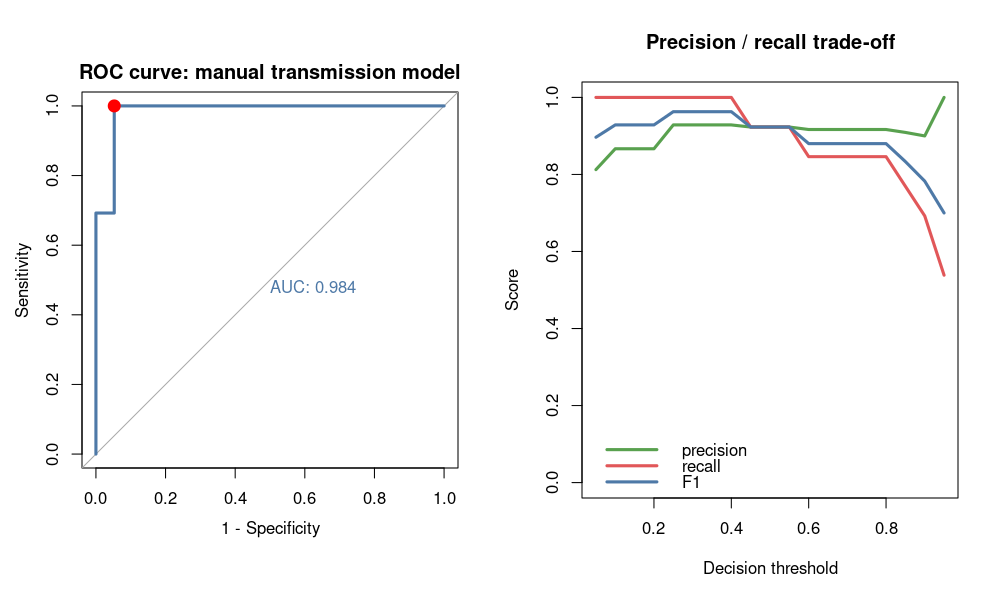

In [4]:
suppressPackageStartupMessages(library(pROC))
roc_obj <- roc(actual, pred_prob, quiet = TRUE)
cat("AUC:", round(auc(roc_obj), 3), "\n")

par(mfrow = c(1, 2), pty = "s")
plot(roc_obj, col = "#4E79A7", lwd = 3, legacy.axes = TRUE, print.auc = TRUE,
     main = "ROC curve: manual transmission model")
best <- coords(roc_obj, "best", ret = c("threshold", "specificity", "sensitivity"))
points(best$specificity, best$sensitivity, pch = 19, cex = 1.6, col = "red")

par(pty = "m")
th <- seq(0.05, 0.95, by = 0.05)
mt <- t(sapply(th, metrics_at))
matplot(th, mt[, c("precision", "recall", "F1")], type = "l", lty = 1, lwd = 3,
        col = c("#59A14F", "#E15759", "#4E79A7"), ylim = c(0, 1),
        main = "Precision / recall trade-off", xlab = "Decision threshold", ylab = "Score")
legend("bottomleft", c("precision", "recall", "F1"), col = c("#59A14F", "#E15759", "#4E79A7"), lwd = 3, bty = "n")

## 6. Comparing Models

1. **Visual comparison**: predicted vs actual plots, ROC curves
2. **Cross-validation**: split the data into **k folds**; train on k-1 folds and test on the remaining one, rotating through all folds
3. **Information criteria** (lower = better trade-off between fit and complexity):
$$
AIC = 2k - 2\ln(\hat{L}), \qquad BIC = k\ln(n) - 2\ln(\hat{L})
$$
   where $k$ is the number of parameters and $\hat{L}$ the maximised likelihood. BIC penalises complexity more strongly.
4. **Nested models**: compare a simpler and a more complex model with an **F-test** or **likelihood-ratio test**

In [5]:
lm_model1 <- lm(y ~ x)          # simple linear
lm_model2 <- lm(y ~ x + I(x^2)) # quadratic model

print(data.frame(model = c("linear", "quadratic"),
                 AIC = round(c(AIC(lm_model1), AIC(lm_model2)), 2),
                 BIC = round(c(BIC(lm_model1), BIC(lm_model2)), 2),
                 adj_R2 = round(c(summary(lm_model1)$adj.r.squared, summary(lm_model2)$adj.r.squared), 4)),
      row.names = FALSE)
cat("\nNested F-test (does the x^2 term help?):\n")
anova(lm_model1, lm_model2)

     model   AIC   BIC adj_R2
    linear  0.23  1.14 0.9947
 quadratic -2.09 -0.88 0.9961



Nested F-test (does the x^2 term help?):


,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,8,0.3287273,NA,NA,NA,NA
2,7,0.2135000,1,0.1152273,3.777943,0.09302767


## 7. Overfitting and Cross-Validation

Polynomials of increasing degree always fit the **training** data better. Cross-validation reveals when the extra flexibility starts fitting noise.

In [6]:
set.seed(24)
n <- 60
cv_data <- data.frame(x = runif(n, 0, 10))
cv_data$y <- 3 + 2 * sin(cv_data$x / 1.5) + rnorm(n, 0, 0.6)

k <- 5
folds <- sample(rep(1:k, length.out = n))
degrees <- 1:12

rmse <- function(a, b) sqrt(mean((a - b)^2))
results <- t(sapply(degrees, function(d) {
  train_err <- rmse(cv_data$y, fitted(lm(y ~ poly(x, d), data = cv_data)))
  cv_err <- mean(sapply(1:k, function(f) {
    fit <- lm(y ~ poly(x, d), data = cv_data[folds != f, ])
    rmse(cv_data$y[folds == f], predict(fit, cv_data[folds == f, ]))
  }))
  c(degree = d, train_RMSE = train_err, cv_RMSE = cv_err)
}))
print(round(results, 3))
best_d <- results[which.min(results[, "cv_RMSE"]), "degree"]
cat("\nBest degree by 5-fold CV:", best_d, "\n")

      degree train_RMSE cv_RMSE
 [1,]      1      1.114   1.185
 [2,]      2      1.074   1.163
 [3,]      3      0.617   0.679
 [4,]      4      0.607   0.659
 [5,]      5      0.607   0.674
 [6,]      6      0.607   0.664
 [7,]      7      0.605   0.676
 [8,]      8      0.598   0.775
 [9,]      9      0.598   0.709
[10,]     10      0.579   2.276
[11,]     11      0.569   1.601
[12,]     12      0.565   1.142



Best degree by 5-fold CV: 4 


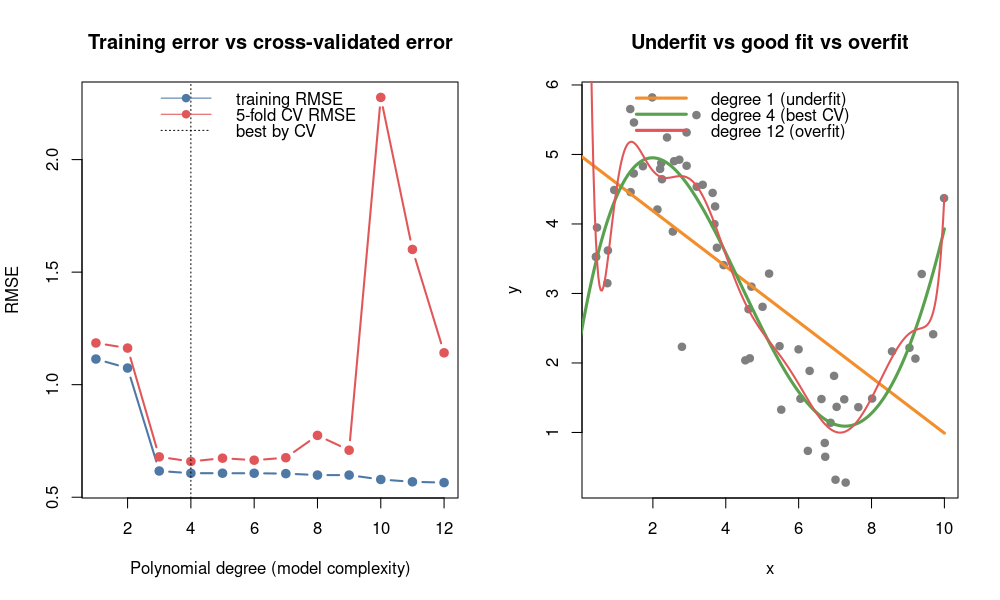

In [7]:
par(mfrow = c(1, 2))
matplot(results[, "degree"], results[, c("train_RMSE", "cv_RMSE")], type = "b", pch = 19, lty = 1, lwd = 2,
        col = c("#4E79A7", "#E15759"), main = "Training error vs cross-validated error",
        xlab = "Polynomial degree (model complexity)", ylab = "RMSE")
abline(v = best_d, lty = 3)
legend("topright", c("training RMSE", "5-fold CV RMSE", "best by CV"), col = c("#4E79A7", "#E15759", "black"),
       lty = c(1, 1, 3), pch = c(19, 19, NA), bty = "n")

grid <- data.frame(x = seq(0, 10, length.out = 300))
plot(cv_data$x, cv_data$y, pch = 19, col = "grey50", main = "Underfit vs good fit vs overfit", xlab = "x", ylab = "y")
lines(grid$x, predict(lm(y ~ poly(x, 1), cv_data), grid), col = "#F28E2B", lwd = 3)
lines(grid$x, predict(lm(y ~ poly(x, best_d), cv_data), grid), col = "#59A14F", lwd = 3)
lines(grid$x, predict(lm(y ~ poly(x, 12), cv_data), grid), col = "#E15759", lwd = 2)
legend("topright", c("degree 1 (underfit)", paste("degree", best_d, "(best CV)"), "degree 12 (overfit)"),
       col = c("#F28E2B", "#59A14F", "#E15759"), lwd = 3, bty = "n")

*Insight: Training error only goes down as complexity grows; cross-validated error falls, bottoms out, then rises. That U-shape is the **bias–variance trade-off**, and the bottom of the U is the model to choose.*

## Real-World Use Case or Analogy

- **Regression metrics**: predicting house prices. RMSE tells you the typical error in currency units; $R^2$ tells you how much of the price variation the model explains.
- **Classification metrics**: a spam filter. High recall catches all spam but may hide real emails (low precision); high precision never hides real emails but lets some spam through. F1 balances the two.
- **Cross-validation**: a student who memorises last year's exam answers (overfitting) scores 100% on practice tests and fails the real exam. Cross-validation is a set of **unseen** practice exams.
- **Model comparison**: choosing between a simple and a fancy recipe — you want the best result without unnecessary complexity (AIC/BIC formalise this).